# Лабораторная 3 — компактная версия

$$u_t=((1+x)u_x)_x-u_x-u+f,\quad x,t\in[0,1].$$

Проверочная модель: $u_*=e^{-t}(1+x+x^2)$, $f=-2(1+x)e^{-t}$, $u_0=1+x+x^2$.

- Дирихле: $u(0,t)=e^{-t}$, $u(1,t)=3e^{-t}$.
- Нейман: $u_x(0,t)=e^{-t}$, $u_x(1,t)=3e^{-t}$.
- Робин: $-\lambda u_x(0,t)+u(0,t)=0$, $\lambda u_x(1,t)+u(1,t)=9e^{-t}$.

Неявная схема, прогонка внутри цикла; своих функций нет. N=80, M=6400.


Дирихле: ошибка при t=1 = 0.00039437; на всей сетке = 0.00082884; невязка границ = 0.00e+00


Неймана: ошибка при t=1 = 0.02863340; на всей сетке = 0.02871350; невязка границ = 8.79e-14


Робина: ошибка при t=1 = 0.01203773; на всей сетке = 0.01515894; невязка границ = 9.15e-14



Тип, x, численное, точное, ошибка:
[[1.00000000e+00 0.00000000e+00 3.67879441e-01 3.67879441e-01
  0.00000000e+00]
 [1.00000000e+00 2.50000000e-01 4.83154452e-01 4.82841767e-01
  3.12685380e-04]
 [1.00000000e+00 5.00000000e-01 6.44182194e-01 6.43789022e-01
  3.93171970e-04]
 [1.00000000e+00 7.50000000e-01 8.51001080e-01 8.50721208e-01
  2.79872360e-04]
 [1.00000000e+00 1.00000000e+00 1.10363832e+00 1.10363832e+00
  0.00000000e+00]
 [2.00000000e+00 0.00000000e+00 3.95091938e-01 3.67879441e-01
  2.72124963e-02]
 [2.00000000e+00 2.50000000e-01 5.08931263e-01 4.82841767e-01
  2.60894969e-02]
 [2.00000000e+00 5.00000000e-01 6.69855447e-01 6.43789022e-01
  2.60664254e-02]
 [2.00000000e+00 7.50000000e-01 8.77679530e-01 8.50721208e-01
  2.69583223e-02]
 [2.00000000e+00 1.00000000e+00 1.13227172e+00 1.10363832e+00
  2.86334001e-02]
 [3.00000000e+00 0.00000000e+00 3.77588778e-01 3.67879441e-01
  9.70933704e-03]
 [3.00000000e+00 2.50000000e-01 4.93203396e-01 4.82841767e-01
  1.03616294e-02]
 [3.

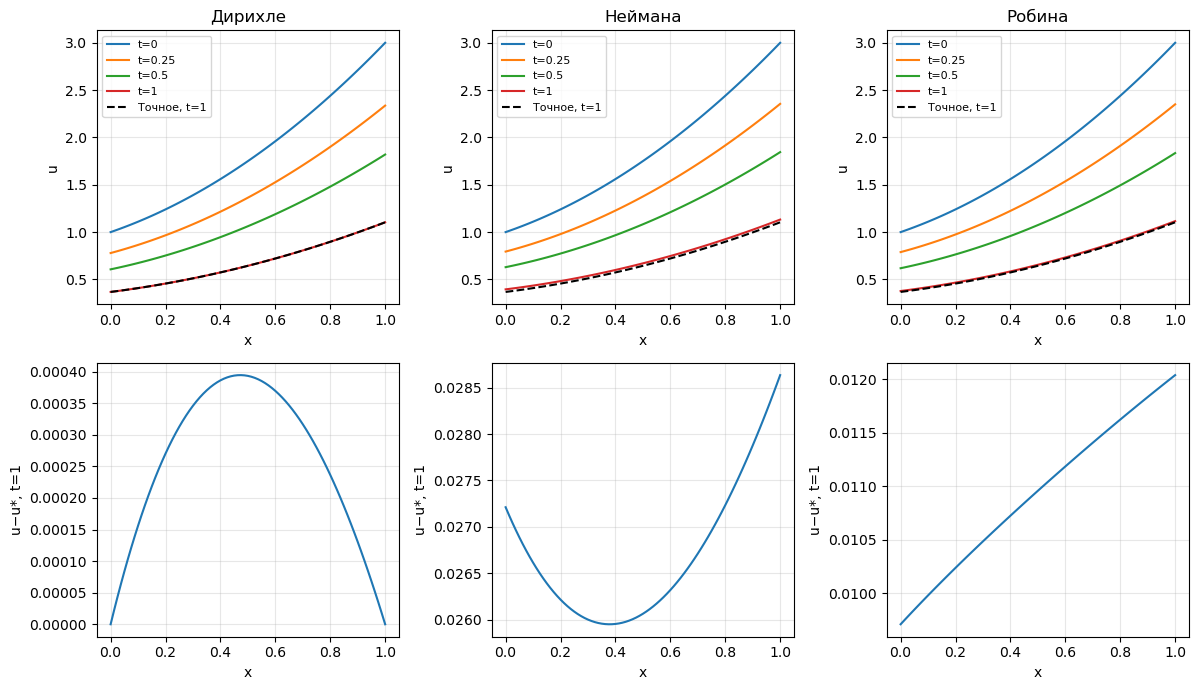

In [1]:
%matplotlib inline
# ## Граничные условия — компактная версия
# u_t=((1+x)*u_x)_x-u_x-u+f; x,t ∈ [0,1].
# Модель выбрана для проверки: u*=exp(-t)*(1+x+x²), f=-2*(1+x)*exp(-t).
# Дирихле, Нейман, Робин; неявная схема, прогонка внутри цикла, без своих функций.

import numpy as np; import matplotlib.pyplot as plt
from pathlib import Path
root = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
out = root/'results/compressed'; out.mkdir(parents=True,exist_ok=True)
N = 80; M = N*N; h = 1/N; tau = 1/M; x = np.linspace(0,1,N+1); t = np.linspace(0,1,M+1)
lam = 1+(x[:-1]+x[1:])/2; exact = np.exp(-t[:,None])*(1+x+x*x)
names = ['Дирихле','Неймана','Робина']; table = []; errors = []
fig, ax = plt.subplots(2,3,figsize=(12,7))

for k,name in enumerate(names):
    # Границы: -κλu_x=ηu+νμ₁ слева, κλu_x=ηu+νμ₂ справа.
    kappa, eta, nu = [(0.,-1.,1.),(1.,0.,-1.),(1.,-1.,-1.)][k]
    mu1 = [1,1,0][k]*np.exp(-t); mu2 = [3,-6,-9][k]*np.exp(-t)
    a = np.r_[-tau*(lam[:-1]/h**2+1/h),-kappa*lam[-1]/h]
    b = np.r_[kappa*lam[0]/h-eta,1+tau*((lam[:-1]+lam[1:])/h**2+1/h+1),kappa*lam[-1]/h-eta]
    c = np.r_[-kappa*lam[0]/h,-tau*lam[1:]/h**2]
    u = np.zeros((M+1,N+1)); u[0] = 1+x+x*x
    for j in range(M):
        rhs = np.r_[nu*mu1[j+1],u[j,1:-1]-2*tau*(1+x[1:-1])*np.exp(-t[j+1]),nu*mu2[j+1]]
        alpha = np.zeros(N); beta = np.zeros(N+1); alpha[0] = c[0]/b[0]; beta[0] = rhs[0]/b[0]
        for i in range(1,N+1):
            z = b[i]-a[i-1]*alpha[i-1]
            if i < N: alpha[i] = c[i]/z
            beta[i] = (rhs[i]-a[i-1]*beta[i-1])/z
        u[j+1,-1] = beta[-1]
        for i in range(N-1,-1,-1): u[j+1,i] = beta[i]-alpha[i]*u[j+1,i+1]

    r1 = -kappa*lam[0]*(u[1:,1]-u[1:,0])/h-eta*u[1:,0]-nu*mu1[1:]
    r2 = kappa*lam[-1]*(u[1:,-1]-u[1:,-2])/h-eta*u[1:,-1]-nu*mu2[1:]
    boundary_error = max(abs(r1).max(),abs(r2).max()); error = abs(u-exact).max(); final_error = max(abs(u[-1]-exact[-1]))
    A = np.diag(b)+np.diag(a,-1)+np.diag(c,1)
    assert boundary_error < 1e-9 and max(abs(np.linalg.solve(A,rhs)-u[-1])) < 1e-9 and np.isfinite(u).all()
    print(f'{name}: ошибка при t=1 = {final_error:.8f}; на всей сетке = {error:.8f}; невязка границ = {boundary_error:.2e}')
    errors.append([k+1,error,final_error,boundary_error])
    np.savez_compressed(out/f'type{k+1}.npz',x=x,t=t,u=u,exact=exact,mu1=mu1,mu2=mu2,kappa=kappa,eta=eta,nu=nu)
    np.savetxt(out/f'type{k+1}.csv',np.column_stack([x,u[-1],exact[-1],abs(u[-1]-exact[-1])]),delimiter=',',header='x,u_t1,exact_t1,abs_error',comments='')
    for i in [0,N//4,N//2,3*N//4,N]: table.append([k+1,x[i],u[-1,i],exact[-1,i],abs(u[-1,i]-exact[-1,i])])
    for time in [0.,0.25,0.5,1.]:
        j = round(time/tau); ax[0,k].plot(x,u[j],label=f't={t[j]:g}')
    ax[0,k].plot(x,exact[-1],'k--',label='Точное, t=1'); ax[0,k].set(title=name,xlabel='x',ylabel='u'); ax[0,k].legend(fontsize=8)
    ax[1,k].plot(x,u[-1]-exact[-1]); ax[1,k].set(xlabel='x',ylabel='u−u*, t=1')

np.savetxt(out/'values.csv',table,delimiter=',',header='type,x,u_t1,exact_t1,abs_error',comments='')
np.savetxt(out/'errors.csv',errors,delimiter=',',header='type,max_error,final_error,boundary_residual',comments='')
print('\nТип, x, численное, точное, ошибка:'); print(np.array(table))
for axis in ax.flat: axis.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(out/'solution.png',dpi=150); plt.show()

# ### Вывод
# При t=1 ошибки: Дирихле 0.00039437, Нейман 0.02863340, Робин 0.01203773.
# Решение совпадает с полной версией; результаты — в results/compressed/.


## Вывод

Ошибки при t=1: Дирихле — 0.00039437, Нейман — 0.02863340, Робин — 0.01203773. Результаты сохраняются в `results/compressed/`.
